# Slug Test Analysis – Hvorslev and Bouwer–Rice

**Hydraulic Methods · Hydrogeology**

This notebook demonstrates two classical methods for interpreting a slug test. The measurements are from **Well 1 of the exercise**. Both methods fit a straight line to the decaying water-level displacement on semi-logarithmic axes.

**Learning objectives:** determine a characteristic response time, estimate hydraulic conductivity **K**, and compare the geometry-dependent formulations of the two methods.

*Notebook by Tanja Liesch, partly based on code by [Gert Ghysels](https://github.com/VUB-HYDR/slugtest) and [Karl DeBisschop](http://hydrotools.sourceforge.net/).*

## 1. Input data

We initially retain the well dimensions in **ft** and convert the final results from ft/s to m/s. Times are given in seconds. Since **h₀ = 1 ft**, the measured displacements are numerically equal to the normalized values **h(t)/h₀**.

The inputs are defined once and reused in both analyses.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 100,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FT_TO_M = 0.3048

# Well geometry in feet / Brunnengeometrie in ft
rc = 0.083       # effective casing radius / effektiver Brunnenrohrradius
L = 9.0         # screen length / Filterlänge
rew = 0.25      # effective screen radius / effektiver Filterradius
Lw = 18.0       # distance to screen base / Tiefe bis Filterunterkante
M = 26.0        # saturated thickness / wassererfüllte Mächtigkeit

h0 = 1.0        # initial displacement / anfängliche Auslenkung [ft]
times = np.arange(15, dtype=float)  # [s]
h_obs = np.array([1, 0.78, 0.61, 0.48, 0.37, 0.29, 0.22, 0.17,
                  0.13, 0.10, 0.081, 0.062, 0.049, 0.039, 0.030])  # [ft]

assert np.all(h_obs > 0) and h0 > 0
assert len(times) == len(h_obs)
assert min(rc, rew, L, Lw, M) > 0

# Linear regression in log10(h/h0) vs. t / Lineare Regression
log_relative_h = np.log10(h_obs / h0)
slope, intercept = np.polyfit(times, log_relative_h, deg=1)
h_fit = h0 * 10**(slope * times + intercept)
rmse = np.sqrt(np.mean((h_obs - h_fit)**2))  # RMSE in ft


## 2. Hvorslev method

The Hvorslev method uses the approximately exponential decay of normalized displacement **h(t)/h₀**. Time **t** is displayed on a linear axis and **h(t)/h₀** on a logarithmic axis. From the fitted line, **t₃₇** is determined as the time at which the displacement has decreased to 37% of its initial value.

For the well geometry considered here, the approximate equation is:

$$
K = \frac{r_c^2\,\ln(L/r_{ew})}{2L\,t_{37}}
$$

Here **r_c** is the effective casing radius, **r_ew** is the effective screen radius, and **L** is the screen length.

### 2.1 Observations and fitted line

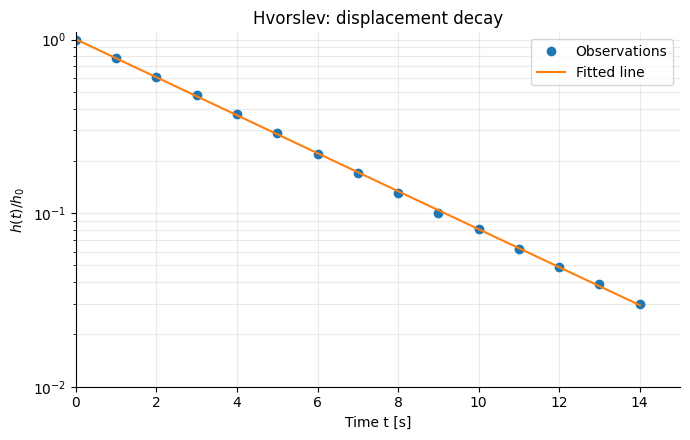

slope = -0.10939 log10-units/s, intercept = 0.00143
RMSE = 0.0035 ft (0.0011 m)


In [2]:
fig, ax = plt.subplots()
ax.semilogy(times, h_obs/h0, 'o', label='Observations')
ax.semilogy(times, h_fit/h0, '-', label='Fitted line')
ax.set(xlabel='Time t [s]', ylabel=r'$h(t)/h_0$',
       title='Hvorslev: displacement decay')
ax.set_xlim(0, 15)
ax.set_ylim(1e-2, 1.1)
ax.grid(True, which='both', alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

print(f"slope = {slope:.5f} log10-units/s, intercept = {intercept:.5f}")
print(f"RMSE = {rmse:.4f} ft ({rmse*FT_TO_M:.4f} m)")

### 2.2 Calculation of t₃₇ and K

The regression line is **log₁₀(h/h₀) = m · t + c**. Setting **h/h₀ = 0.37** yields **t₃₇**. Hydraulic conductivity is subsequently converted into m/s.

In [3]:
t37 = (np.log10(0.37) - intercept) / slope
K_hvorslev_fts = rc**2 * np.log(L/rew) / (2 * L * t37)
K_hvorslev_ms = K_hvorslev_fts * FT_TO_M
print(f"t37 = {t37:.2f} s")
print(f"K (Hvorslev) = {K_hvorslev_fts:.3e} ft/s = {K_hvorslev_ms:.3e} m/s")

t37 = 3.96 s
K (Hvorslev) = 3.463e-04 ft/s = 1.056e-04 m/s


## 3. Bouwer–Rice method

This method also fits a straight line to the logarithm of **h(t)**. Well geometry enters through the dimensionless factor **ln(Rₑ/r_ew)**.

$$
K = \frac{r_c^2\,\ln(R_e/r_{ew})}{2L_e}\,\frac{1}{t}\,\ln\left(\frac{h_0}{h_t}\right)
$$

Here **Lₑ** denotes screen length. The factor **ln(h₀/hₜ)/t** is obtained from the fitted exponential decline.

For a fully penetrating well:

$$
\ln\left(\frac{R_e}{r_{ew}}\right)=\left[\frac{1.1}{\ln(L_w/r_{ew})}+\frac{C}{L_e/r_{ew}}\right]^{-1}
$$

For a partially penetrating well, we use the following approximation as given in the exercise:

$$
\ln\left(\frac{R_e}{r_{ew}}\right)=\left[\frac{1.1}{\ln(L_w/r_{ew})}+\frac{A+B\ln((M-L_w)r_{ew})}{L_e/r_{ew}}\right]^{-1}
$$

The empirical coefficients **A**, **B**, and **C** are computed with DeBisschop's approximation functions. **Note:** The original implementation assumes the exercise's specified length-unit convention for the final approximation; it is preserved here.

### 3.1 Empirical coefficients A, B, and C

We retain the piecewise approximations from the original exercise. Here **x = log₁₀(Lₑ/r_ew)**.

In [4]:
Le = L
x = np.log10(Le / rew)

if x < 2.554422663:
    A = 1.638445671 + 0.166908063*x + 0.000740459*np.exp(6.17105281*x - 1.054747686*x*x)
else:
    A = 11.00393028 - 170.7752217*np.exp(-1.509639982*x)

if x < 2.596774459:
    B = 0.174811819 + 0.060059188*x + 0.007965502*np.exp(2.053376868*x - 0.007790328*x*x)
else:
    B = 4.133124586 - 93.06136936*np.exp(-1.435370997*x)

if x < 2.200426117:
    C = 0.074711376 + 1.083958569*x + 0.00557352*np.exp(2.929493814*x - 0.001028433*x*x)
else:
    C = 15.66887372 - 178.4329289*np.exp(-1.322779744*x)

print(f"log10(Le/rew) = {x:.4f}")
print(f"A = {A:.3f}, B = {B:.3f}, C = {C:.3f}")

log10(Le/rew) = 1.5563
A = 2.751, B = 0.459, C = 2.293


### 3.2 Fitting the displacement decay

The observations are the same as before. The Bouwer–Rice method uses **h(t)** directly; because **h₀ = 1 ft**, it is numerically identical to **h(t)/h₀** for this exercise.

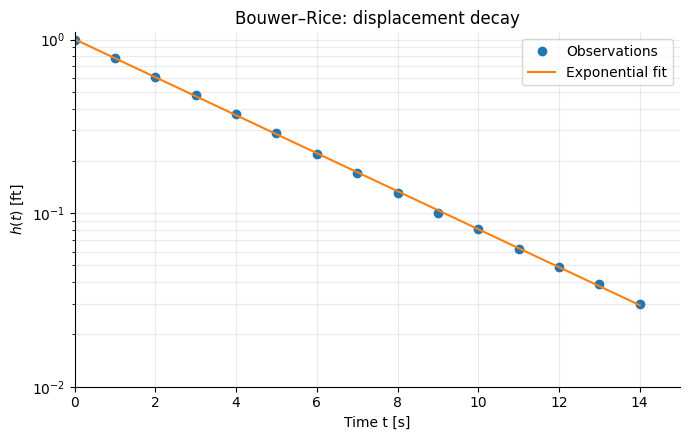

RMSE = 0.0035 ft (0.0011 m)


In [5]:
fig, ax = plt.subplots()
ax.semilogy(times, h_obs, 'o', label='Observations')
ax.semilogy(times, h_fit, '-', label='Exponential fit')
ax.set(xlabel='Time t [s]', ylabel=r'$h(t)$ [ft]',
       title='Bouwer–Rice: displacement decay')
ax.set_xlim(0, 15)
ax.set_ylim(1e-2, 1.1)
ax.grid(True, which='both', alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()
print(f"RMSE = {rmse:.4f} ft ({rmse*FT_TO_M:.4f} m)")

### 3.3 A point on the fitted curve

As an example, we choose **t = 10 s** and calculate the corresponding displacement from the fitted line. The ratio **ln(h₀/hₜ)/t** is independent of time for an exact exponential decay referenced to its fitted initial displacement. Because the fitted intercept may differ slightly from measured **h₀** due to scatter, we consistently use two points on the fitted curve (at **t = 0** and **t = 10 s**).

In [6]:
t_example = 10.0
h_fit_0 = 10**intercept       # fitted initial displacement [ft]
h_fit_t = 10**(slope*t_example + intercept)  # [ft]
rate = np.log(h_fit_0/h_fit_t) / t_example  # [1/s]
print(f"t = {t_example:g} s, h(t) = {h_fit_t:.3f} ft")
print(f"ln(h_fit(0)/h_fit(t))/t = {rate:.5f} 1/s")

t = 10 s, h(t) = 0.081 ft
ln(h_fit(0)/h_fit(t))/t = 0.25188 1/s


### 3.4 Effective radius terms for both geometries

We calculate **ln(Rₑ/r_ew)** for fully and partially penetrating wells to compare the influence of this assumption.

In [7]:
u_full = 1.0 / (1.1/np.log(Lw/rew) + C/(Le/rew))
u_partial = 1.0 / (1.1/np.log(Lw/rew) + (A + B*np.log((M-Lw)*rew))/(Le/rew))
print(f"ln(Re/rew), fully penetrating = {u_full:.5f}")
print(f"ln(Re/rew), partially penetrating = {u_partial:.5f}")

ln(Re/rew), fully penetrating = 3.11629
ln(Re/rew), partially penetrating = 2.91991


### 3.5 Calculation of K

Using the decay rate estimated from the fitted line, we calculate **K** for both well-penetration assumptions.

In [8]:
K_full_fts = rc**2 * u_full / (2 * Le) * rate
K_partial_fts = rc**2 * u_partial / (2 * Le) * rate
K_full_ms = K_full_fts * FT_TO_M
K_partial_ms = K_partial_fts * FT_TO_M
print(f"K (fully penetrating)     = {K_full_ms:.3e} m/s")
print(f"K (partially penetrating) = {K_partial_ms:.3e} m/s")

K (fully penetrating)     = 9.157e-05 m/s
K (partially penetrating) = 8.580e-05 m/s


## 4. Summary and interpretation

Both methods assume an approximately exponential decay of water-level displacement. Their differing treatment of well geometry affects the calculated hydraulic conductivity. For the Bouwer–Rice method, the appropriate equation must be selected according to the actual well and aquifer geometry.

For interpretation, the correct geometry, appropriate model assumptions, and an approximately straight decline on semi-logarithmic axes are especially important.

**Further resources:** [Ghysels – Slugtest code](https://github.com/VUB-HYDR/slugtest); [DeBisschop – Hydrotools](http://hydrotools.sourceforge.net/).

In [9]:
print("Hvorslev:            K = %.3e m/s" % K_hvorslev_ms)
print("Bouwer-Rice (full):  K = %.3e m/s" % K_full_ms)
print("Bouwer-Rice (part):  K = %.3e m/s" % K_partial_ms)

Hvorslev:            K = 1.056e-04 m/s
Bouwer-Rice (full):  K = 9.157e-05 m/s
Bouwer-Rice (part):  K = 8.580e-05 m/s
